# Tentativo 14 — ModernBERT a pezzi (chunk), dal dataset grezzo ai risultati

**La domanda** (proposta di Fabio): ModernBERT legge al più 1024 token per articolo e circa metà degli articoli è più
lunga. Se **spezziamo ogni articolo in pezzi** (chunk), facciamo valutare ogni pezzo da solo e poi mettiamo insieme i
voti dei pezzi, il transformer legge tutto il testo: va meglio? E quanto testo resta fuori oggi?

Tutto in questo notebook, dall'inizio alla fine, sulle **testate solo politiche** con le etichette **NewsGuard 2026**:

1. **Dati grezzi**: i testi dello scraping (due giri di ottobre + terzo giro del 25 ottobre).
2. **Pulizia**, un passo alla volta, con le regole di sempre (tentativi 06–13).
3. **Reti di siti**, per tenere insieme nei fold le testate parenti.
4. **Dataset solo politici**: testate, gruppi, fold (deve tornare uguale al tentativo 13).
5. **Quanto testo resta fuori** dai 1024 token di ModernBERT.
6. **Classificatore a feature** (TF-IDF): il riferimento.
7. **ModernBERT troncato**: solo i primi 1024 token, come finora.
8. **ModernBERT a pezzi**: pezzi da 512 token (64 di sovrapposizione), addestrato e valutato sui pezzi; poi i pezzi si
   mettono insieme in sette modi (maggioranza, media, media geometrica, media pesata per lunghezza, pezzo più sicuro,
   solo il primo pezzo, tutti i pezzi della testata insieme).
9. **Confronto**: F1 a 5 livelli, accuratezza, **binario** (affidabile sì/no) e **tolerant** (±1 livello), con
   intervalli al 95% da un bootstrap per gruppo.

Le funzioni lunghe stanno in `funzioni.py` (prese dai tentativi precedenti). Ogni passo pesante salva il suo
risultato in `Results/cache/`: se il notebook si interrompe e si rilancia, riparte da lì. Fissato il 26 ottobre, prima
dei risultati.

In [1]:
PROVA = False      # True: poche testate, un fold, addestramento brevissimo (per controllare che tutto giri)
N_JOBS = 32        # processi per le parti in parallelo (CPU)

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

import funzioni as F

DATI = Path("Dataset")
GIRI = [DATI / "NuovoScraping_ottobre", DATI / "NuovoScraping_giro3"]
OUT = Path("Results") / ("prova" if PROVA else "")
CACHE = OUT / "cache"; CACHE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
passi = []


def passo(nome, df):
    """Annota quanti articoli e testate restano dopo un passo."""
    passi.append({"passo": nome, "articoli": len(df), "testate": df.domain.nunique()})
    print(f"{nome}: {len(df):,} articoli, {df.domain.nunique():,} testate")


def registra(m):
    riga = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {m}"
    print(riga, flush=True)
    with open(OUT / "avanzamento.log", "a") as f:
        f.write(riga + "\n")

## 1. I dati grezzi

Lo scraping ha visitato le testate NewsGuard in inglese, con un punteggio, che parlano di politica (lista NewsGuard
2022 nei due giri di ottobre, lista 2026 nel terzo giro), e ha salvato fino a 200 articoli per testata: testo estratto,
titolo, data, autore, e l'HTML grezzo della pagina.

Primi filtri, gli stessi di sempre: **più di 100 parole**, **niente doppioni** nella stessa testata (stesso URL o
stesso testo), **solo inglese** (riconoscimento automatico della lingua sulle prime 400 parole).

In [3]:
stati = F.leggi_stati(GIRI)
grezzo = F.leggi_scraping(GIRI).rename(columns={"dominio": "domain", "testo": "text"})
if PROVA:      # in prova: 120 testate a caso tra quelle solo politiche
    ng = F.leggi_newsguard(DATI / "newsguard_2026.csv")
    pol = [d for d in sorted(grezzo.domain.unique()) if str(ng.Topics.get(d, "")).strip() == F.POLITICA]
    grezzo = grezzo[grezzo.domain.isin(set(pd.Series(pol).sample(120, random_state=F.SEED)))].reset_index(drop=True)
print(f"testate tentate: {len(stati):,}; raggiunte: {(~stati.esito.str.startswith('homepage')).sum():,}")
print("esiti dello scraping:", stati.esito.str.replace(r" \(.*\)", "", regex=True).value_counts().to_dict())
passo("testi estratti dallo scraping", grezzo)

testate tentate: 5,113; raggiunte: 2,702
esiti dello scraping: {'homepage irraggiungibile': 2411, 'esauriti gli URL o i tentativi': 1653, 'completata': 1049}
testi estratti dallo scraping: 299,658 articoli, 2,409 testate


In [4]:
f = CACHE / "articoli_base.csv.gz"
if f.exists():
    art = pd.read_csv(f); print("caricato da", f)
else:
    art = grezzo[grezzo.parole > 100]
    art = art.drop_duplicates(["domain", "url"]).drop_duplicates(["domain", "text"])
    art = art.assign(lingua=Parallel(n_jobs=N_JOBS, batch_size=200)(delayed(F.lingua)(t) for t in art.text))
    art = art[art.lingua == "en"].reset_index(drop=True).rename_axis("article_id").reset_index()
    art.to_csv(f, index=False)
passo("1. più di 100 parole, senza doppioni, in inglese", art)

1. più di 100 parole, senza doppioni, in inglese: 189,189 articoli, 1,957 testate


## 2. La pulizia, un passo alla volta

Senza mai guardare le etichette. Lo scopo è togliere dal testo tutto quello che **riconosce il sito** invece di dire
qualcosa sull'articolo (firme, inviti, piè di pagina, titolo e data in testa, link), e gli articoli **copiati** tra
testate (lo stesso testo non deve stare nel training e nel test).

In [5]:
art["data"] = pd.to_datetime(art.data, errors="coerce")
art["norm"] = art.text.map(F.normalizza)
# 2.1 copie identiche nella stessa testata: si tiene la più vecchia
import hashlib
art["impronta"] = art.norm.map(lambda s: hashlib.md5(s.encode()).hexdigest())
art = art.sort_values("data").drop_duplicates(["domain", "impronta"]).sort_index()
passo("2.1 senza copie identiche nella stessa testata", art)

2.1 senza copie identiche nella stessa testata: 189,158 articoli, 1,957 testate


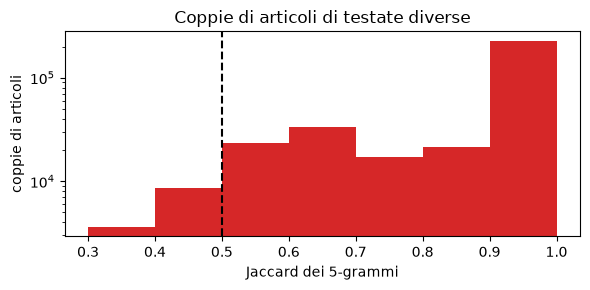

articoli con una copia in un'altra testata: 45,479 (24.0%); coppie: 323,640
si tolgono al passo 4, dopo aver formato i gruppi: tra testate dello stesso gruppo le copie restano


In [6]:
# 2.2 copie tra testate diverse: articoli quasi uguali (Jaccard dei 5-grammi di parole >= 0.5, stima MinHash)
f = CACHE / "copie_tra_testate.csv"
if f.exists():
    copie = pd.read_csv(f); print("caricato da", f)
else:
    coppie = F.coppie_simili(art.reset_index(drop=True), 0.3, N_JOBS)
    tra = coppie[coppie.testata_a != coppie.testata_b]
    plt.figure(figsize=(6, 3)); plt.hist(tra.jaccard, bins=[0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001], color="tab:red")
    plt.axvline(0.5, color="k", ls="--"); plt.yscale("log"); plt.xlabel("Jaccard dei 5-grammi"); plt.ylabel("coppie di articoli")
    plt.title("Coppie di articoli di testate diverse"); plt.tight_layout(); plt.show()
    copie = tra[tra.jaccard >= 0.5]; copie.to_csv(f, index=False)
con_copia = set(copie.articolo_a) | set(copie.articolo_b)
print(f"articoli con una copia in un'altra testata: {len(con_copia):,} ({len(con_copia) / len(art):.1%}); coppie: {len(copie):,}")
print("si tolgono al passo 4, dopo aver formato i gruppi: tra testate dello stesso gruppo le copie restano")

In [7]:
# 2.3 solo articoli dal 2025 (le testate li pubblicano oggi: il periodo delle etichette NewsGuard 2026)
print("articoli per anno:", art.data.dt.year.value_counts().sort_index().loc[2018:].to_dict())
art = art[art.data >= "2025-01-01"]
passo("2.3 pubblicati dal 2025", art)

articoli per anno: {2018.0: 1919, 2019.0: 2556, 2020.0: 2377, 2021.0: 2858, 2022.0: 4641, 2023.0: 5021, 2024.0: 11109, 2025.0: 10303, 2026.0: 138867}


2.3 pubblicati dal 2025: 149,170 articoli, 1,819 testate


In [8]:
# 2.4 frasi ripetute dalla stessa testata in almeno 3 articoli (firme, inviti a iscriversi, piè di pagina)
tutti = pd.read_csv(CACHE / "articoli_base.csv.gz", usecols=["domain", "text"])          # le ripetizioni si contano su tutti gli articoli
tutti = tutti.assign(norm=tutti.text.map(F.normalizza)).drop_duplicates(["domain", "norm"])
parole_prima = art.text.str.split().str.len().sum()
testi, esempi = F.togli_frasi_ripetute(art, tutti)
art = art.assign(text=testi)
print(f"parole tolte: {1 - art.text.str.split().str.len().sum() / parole_prima:.1%}")
print("le frasi ripetute più spesso (articoli, testata, frase):")
for n, d, f in esempi:
    print(f"  {n:4d}  {d:28s} {f[:90]}")

parole tolte: 4.9%
le frasi ripetute più spesso (articoli, testata, frase):
   200  truthout.org                 we lost 15 percent of our readership overnight
   200  truthout.org                 we are fundraising right now to meet our basic operating expenses
   200  truthout.org                 truthout is one of only a few platforms for justice oriented grassroots journalism
   200  truthout.org                 today we face an existential threat
   200  truthout.org                 this was a readership we painstakingly built over decades and it vanished because google c
   200  truthout.org                 if you can support truthout with a one time or monthly donation you will make a significan
   200  truthout.org                 due to google s launch of ai search we ve seen a drastic plunge in our site traffic and as
   200  truthout.org                 anything you can do makes a difference we appreciate your support


In [9]:
# 2.5 titolo e data ripetuti all'inizio del testo (li aggiunge il sito)
esiti = [F.togli_cornice(t, ti) for t, ti in zip(art.text, art.titolo.fillna(""))]
art = art.assign(text=[e[0] for e in esiti])
print(f"titolo tolto dall'inizio: {sum(e[1] for e in esiti):,} articoli; data tolta: {sum(e[2] for e in esiti):,} articoli")
# 2.6 link, firme di tweet e scritte dei post incorporati
prima = art.text.str.len().sum()
art = art.assign(text=art.text.map(F.togli_incorporati))
art["norm"] = art.text.map(F.normalizza)
print(f"caratteri tolti con link e incorporati: {1 - art.text.str.len().sum() / prima:.1%}")

titolo tolto dall'inizio: 36,724 articoli; data tolta: 4,352 articoli


caratteri tolti con link e incorporati: 0.4%


In [10]:
# 2.7 doppioni quasi uguali nella stessa testata (si tiene il più vecchio) e 2.8 almeno 100 parole dopo la pulizia
f = CACHE / "articoli_puliti.csv.gz"
if f.exists():
    art = pd.read_csv(f, parse_dates=["data"]); print("caricato da", f)
else:
    art, tolti = F.togli_doppioni_in_testata(art.reset_index(drop=True), 0.5, N_JOBS)
    print(f"doppioni tolti: {tolti:,}")
    art = art[art.text.str.split().str.len() >= 100]
    art[["article_id", "domain", "url", "titolo", "data", "autore", "text"]].to_csv(f, index=False)
passo("2.7-2.8 senza doppioni nella testata, almeno 100 parole", art)
pd.DataFrame(passi).set_index("passo")

doppioni tolti: 839


2.7-2.8 senza doppioni nella testata, almeno 100 parole: 143,106 articoli, 1,816 testate


,articoli,testate
passo,,
testi estratti dallo scraping,299658,2409
"1. più di 100 parole, senza doppioni, in inglese",189189,1957
2.1 senza copie identiche nella stessa testata,189158,1957
2.3 pubblicati dal 2025,149170,1819
"2.7-2.8 senza doppioni nella testata, almeno 100 parole",143106,1816


## 3. Le reti di siti

Molte testate fanno parte di **reti** (stesso proprietario o stessa gestione: siti con lo stesso modello, che si
copiano gli articoli). Se una testata della rete sta nel training e un'altra nel test, il modello "riconosce la rete"
invece di valutare l'affidabilità. Le reti si trovano **senza guardare le etichette**, da cinque tracce: articoli
copiati, stessi codici di account (pubblicità, statistiche), stesso titolare legale (privacy policy esterna), stesso
dominio o redirect, stessi autori.

In [11]:
f = CACHE / "reti.csv"
if f.exists():
    rete = pd.read_csv(f).set_index("domain").rete.to_dict(); print("caricato da", f)
else:
    base = pd.read_csv(CACHE / "articoli_base.csv.gz", usecols=["article_id", "domain", "autore"])
    rete, collegamenti, per_segnale = F.reti_di_testate(base, copie, GIRI, DATI / "disconnect_services.json", N_JOBS)
    print("coppie di testate collegate, per traccia:", dict(per_segnale))
    pd.Series(rete, name="rete").rename_axis("domain").to_csv(f)
dim = pd.Series(rete).value_counts()
print(f"{len(dim):,} reti; testate in una rete con altre: {dim[dim > 1].sum():,}; le reti più grandi: {dim.head(8).tolist()}")

coppie di testate collegate, per traccia: {'copie': 23555, 'codice adsense': 1106, 'codice analytics': 261, 'codice tag_manager': 275, 'codice facebook_pixel': 144, 'codice facebook_app': 85, 'codice chartbeat': 32, 'codice comscore': 2, 'titolare legale': 1369, 'dominio: stesso dominio registrato': 89, 'dominio: redirect allo stesso dominio': 248, 'autori': 87296}
683 reti; testate in una rete con altre: 1,381; le reti più grandi: [534, 191, 161, 40, 33, 26, 21, 18]


## 4. Il dataset solo politici

- **Etichetta**: il livello NewsGuard **2026** dal punteggio (l1 < 40, l2 40–59, l3 60–74, l4 75–99, l5 = 100);
  **binario**: affidabile = punteggio ≥ 60 (l3–l5).
- **Solo politici**: le testate che per NewsGuard 2026 hanno **un solo argomento**, "Political news or commentary".
- **Gruppi** = reti ∪ stesso proprietario ∪ stesso Parent Domain (NewsGuard 2022 e 2026). Un gruppo sta tutto nel
  training o tutto nel test; poi si tolgono le **copie tra gruppi diversi** (si tiene la più vecchia).
- **Testate valutate** (il test): almeno 20 articoli e al più 5 per gruppo, a caso senza guardare le etichette.
  **Di solo training**: almeno 10 articoli, con peso min(1, 5/n). **5 fold per gruppo**, stratificati per livello.

In [12]:
n26, n22 = F.leggi_newsguard(DATI / "newsguard_2026.csv"), F.leggi_newsguard(DATI / "newsguard_2022.csv")
art["score"] = art.domain.map(n26.Score)
argomenti = art.domain.map(n26.Topics).fillna("").str.split(",").map(lambda x: [a.strip() for a in x if a.strip()])
art = art[art.score.notna() & argomenti.map(lambda x: x == [F.POLITICA]).to_numpy()].copy()
art["label"] = F.livello(art.score)
passo("4.1 testate con un punteggio 2026 e il solo argomento politico", art)
gruppo = F.gruppi(art.domain.unique(), rete, [n22, n26])
art["gruppo"] = art.domain.map(gruppo)
art, tolti = F.togli_copie_tra_gruppi(art, copie)
passo(f"4.2 senza copie tra gruppi diversi ({tolti} articoli)", art)

4.1 testate con un punteggio 2026 e il solo argomento politico: 43,728 articoli, 532 testate


4.2 senza copie tra gruppi diversi (198 articoli): 43,530 articoli, 532 testate


In [13]:
t = F.testate_e_fold(art, min_valutate=20, per_gruppo=5, min_training=5)
t = F.ricalcola_peso(t[t.articoli >= 10])            # come nel tentativo 13: via le testate con meno di 10 articoli
art = art[art.domain.isin(t.index)].copy()
for c in ["valutazione", "fold", "peso"]:
    art[c] = art.domain.map(t[c])
t["orientamento"] = t.index.map(n26.Orientation).fillna("nessuno")
passo("4.3 testate con almeno 10 articoli (training)", art)
passi.append({"passo": "4.4 di cui valutate (il test)", "articoli": int(art.valutazione.sum()), "testate": int(t.valutazione.sum())})
print(f"testate: {len(t)} ({t.valutazione.sum()} valutate in {t[t.valutazione].gruppo.nunique()} gruppi)")
display(pd.crosstab([t.valutazione.map({True: "valutate", False: "solo training"}), t.orientamento],
                    t.label.map(dict(enumerate(F.LIVELLI))), margins=True))
# controllo: deve tornare il dataset del tentativo 13
rif = DATI / "riferimento_t13_fold.csv"
if rif.exists() and not PROVA:
    r = pd.read_csv(rif).set_index("domain")
    print("uguale al tentativo 13?", {"stesse testate": set(r.index) == set(t.index),
          "stesse valutate": set(r.index[r.valutazione]) == set(t.index[t.valutazione]),
          "stesse etichette": (r.label.reindex(t.index) == t.label).all(),
          "stessi fold delle valutate": (r.fold_gruppo.reindex(t.index[t.valutazione]) == t.fold[t.valutazione]).all()})
pd.DataFrame(passi).set_index("passo")

4.3 testate con almeno 10 articoli (training): 42,219 articoli, 323 testate
testate: 323 (254 valutate in 191 gruppi)


label                       l1  l2  l3  l4  l5  All
valutazione   orientamento                         
solo training Left           1  19   0   6   0   26
              Right          7  17   5   3   0   32
              nessuno        0   2   0   7   2   11
valutate      Left           3  15   6  38  16   78
              Right         37  36  18  25   4  120
              nessuno        6   4   7  19  20   56
All                         54  93  36  98  42  323

uguale al tentativo 13? {'stesse testate': True, 'stesse valutate': True, 'stesse etichette': np.True_, 'stessi fold delle valutate': np.True_}


,articoli,testate
passo,,
testi estratti dallo scraping,299658,2409
"1. più di 100 parole, senza doppioni, in inglese",189189,1957
2.1 senza copie identiche nella stessa testata,189158,1957
2.3 pubblicati dal 2025,149170,1819
"2.7-2.8 senza doppioni nella testata, almeno 100 parole",143106,1816
4.1 testate con un punteggio 2026 e il solo argomento politico,43728,532
4.2 senza copie tra gruppi diversi (198 articoli),43530,532
4.3 testate con almeno 10 articoli (training),42219,323
4.4 di cui valutate (il test),36068,254


## 5. Quanto testo resta fuori da ModernBERT

ModernBERT legge al più 1024 token (pezzi di parola) per articolo: il resto viene tagliato. Quanto?

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Token indices sequence length is longer than the specified maximum sequence length for this model (8678 > 8192). Running this sequence through the model will result in indexing errors


in tutto si perde il 34.6% dei token del dataset


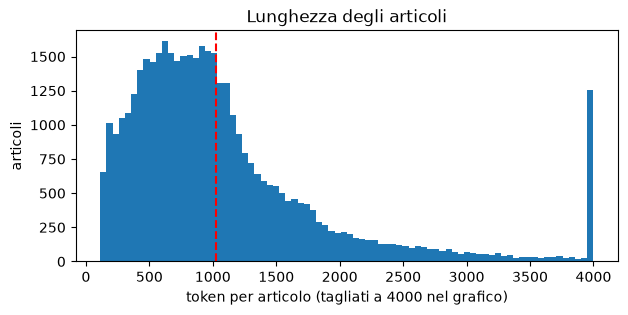

,token per articolo (mediana),oltre 512 token,oltre 1024 token,testo tagliato (media sugli articoli)
label,,,,
l1,709.5,0.670,0.317,0.110
l2,910.0,0.821,0.374,0.101
l3,741.0,0.730,0.311,0.101
l4,925.0,0.798,0.433,0.155
l5,1197.5,0.861,0.589,0.250
tutti,896.0,0.784,0.404,0.139


In [14]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
art = art.reset_index(drop=True)
art["ids"] = tok(art.text.tolist(), add_special_tokens=False)["input_ids"]
art["token"] = art.ids.str.len()
lim = 1022                                            # 1024 meno i due token speciali
fuori = (art.token - lim).clip(lower=0)
riass = pd.DataFrame({
    "token per articolo (mediana)": art.groupby("label").token.median(),
    "oltre 512 token": art.groupby("label").token.apply(lambda x: (x > 510).mean()),
    "oltre 1024 token": art.groupby("label").token.apply(lambda x: (x > lim).mean()),
    "testo tagliato (media sugli articoli)": (fuori / art.token).groupby(art.label).mean(),
}).rename(index=dict(enumerate(F.LIVELLI)))
riass.loc["tutti"] = [art.token.median(), (art.token > 510).mean(), (art.token > lim).mean(), (fuori / art.token).mean()]
print(f"in tutto si perde il {fuori.sum() / art.token.sum():.1%} dei token del dataset")
plt.figure(figsize=(7, 3)); plt.hist(art.token.clip(upper=4000), bins=80); plt.axvline(1024, color="r", ls="--")
plt.xlabel("token per articolo (tagliati a 4000 nel grafico)"); plt.ylabel("articoli"); plt.title("Lunghezza degli articoli"); plt.show()
riass.round(3)

## 6. Il classificatore a feature (il riferimento)

TF-IDF (parole e coppie di parole, al più 100.000) + regressione logistica, come nei tentativi 06–13: per ogni fold si
addestra sulle testate degli altri fold (con i pesi e le classi bilanciate) e si predicono gli articoli delle testate
valutate del fold. C scelto tra 0,1, 1, 10, 100 con una validazione interna per gruppi sul solo training. Per testata:
**voto di maggioranza** degli articoli (come sempre) e, accanto, **media delle probabilità**.

In [15]:
f = CACHE / "feature_articoli.csv"
if f.exists():
    pf = pd.read_csv(f); print("caricato da", f)
else:
    t0 = time.time()
    dati = art[["article_id", "domain", "text", "label", "gruppo", "valutazione", "fold", "peso"]]
    if PROVA:
        dati = dati.assign(fold=np.where(dati.fold == 1, 1, 2))
    pf, scelti = F.classificatore_feature(dati, griglia=(1,) if PROVA else (0.1, 1, 10, 100), n_jobs=1 if PROVA else 5)
    pf.to_csv(f, index=False)
    print(f"fatto in {(time.time() - t0) / 60:.1f} min; C scelto per fold: {scelti}")
print(f"{len(pf):,} articoli di test di {pf.domain.nunique()} testate")

fatto in 14.5 min; C scelto per fold: [100, 10, 1, 10, 100]
36,068 articoli di test di 254 testate


## 7. ModernBERT troncato (come finora)

ModernBERT-base, solo i **primi 1024 token** di ogni articolo. Ricetta dei tentativi precedenti: 2 epoche, a ogni
epoca al più 5 testate per gruppo (diverse a ogni epoca) e **20 articoli per testata**, classi bilanciate sulle testate
pesate, lr 2e-5, batch effettivo 32, seme 42. Per testata: **media delle probabilità** degli articoli e, accanto, voto.

In [16]:
U = art[["article_id", "domain"]].assign(pezzo=0, ids=[x[:lim] for x in art.ids])
U["token"] = U.ids.str.len()
cartella = CACHE / "modernbert_troncato"; cartella.mkdir(exist_ok=True)
folds = [1] if PROVA else sorted(t.fold.unique())
pt = pd.concat([F.addestra_e_predici(U, t, f, cartella, registra, 1024, per_testata_epoca=4 if PROVA else 20, epoche=1 if PROVA else 2)
                for f in folds], ignore_index=True)
print(f"{len(pt):,} articoli di test di {pt.domain.nunique()} testate")

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


2026-10-26 15:01:13  fold 1 epoca 1/2: 4388 unità, loss 1.5495 (153 s)


2026-10-26 15:04:09  fold 1 epoca 2/2: 4388 unità, loss 1.3626 (330 s)


...

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-26 15:25:36  fold 5 epoca 1/2: 4417 unità, loss 1.5383 (154 s)


2026-10-26 15:28:09  fold 5 epoca 2/2: 4417 unità, loss 1.3421 (308 s)


2026-10-26 15:28:57  fold 5: finito, 7955 unità di test, memoria GPU massima 5.1 GB


36,068 articoli di test di 254 testate


## 8. ModernBERT a pezzi (la proposta)

Ogni articolo si divide in **pezzi da 512 token** consecutivi, con **64 token di sovrapposizione** (per non tagliare
le frasi a metà). Il modello si **addestra sui pezzi** (ogni pezzo con l'etichetta della sua testata) e **valuta ogni
pezzo da solo**. Stessa ricetta del troncato e **stesso numero di token per testata a ogni epoca** (40 pezzi da 512
invece di 20 articoli da 1024): il confronto misura solo l'effetto di leggere tutto il testo.

In [17]:
righe = []
for a, d, ids in zip(art.article_id, art.domain, art.ids):
    for k, pezzo in enumerate(F.unita(ids, 510, passo=446)):
        righe.append((a, d, k, pezzo, len(pezzo)))
Up = pd.DataFrame(righe, columns=["article_id", "domain", "pezzo", "ids", "token"])
n_pezzi = Up.groupby("article_id").size()
print(f"{len(Up):,} pezzi da al più 512 token per {len(art):,} articoli; pezzi per articolo: mediana {n_pezzi.median():.0f}, "
      f"media {n_pezzi.mean():.1f}, massimo {n_pezzi.max()}; articoli con un solo pezzo: {(n_pezzi == 1).mean():.0%}")
cartella = CACHE / "modernbert_pezzi"; cartella.mkdir(exist_ok=True)
pp = pd.concat([F.addestra_e_predici(Up, t, f, cartella, registra, 512, per_testata_epoca=8 if PROVA else 40, epoche=1 if PROVA else 2)
                for f in folds], ignore_index=True)
print(f"{len(pp):,} pezzi di test, {pp.article_id.nunique():,} articoli, {pp.domain.nunique()} testate")

127,719 pezzi da al più 512 token per 42,219 articoli; pezzi per articolo: mediana 2, media 3.0, massimo 309; articoli con un solo pezzo: 22%


Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-26 15:31:33  fold 1 epoca 1/2: 8906 unità, loss 1.5047 (151 s)


2026-10-26 15:34:18  fold 1 epoca 2/2: 8906 unità, loss 1.2681 (316 s)


2026-10-26 15:35:45  fold 1: finito, 23712 unità di test, memoria GPU massima 5.1 GB


...

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-26 15:57:49  fold 5 epoca 1/2: 8921 unità, loss 1.4994 (157 s)


2026-10-26 16:00:58  fold 5 epoca 2/2: 8921 unità, loss 1.2486 (345 s)


2026-10-26 16:02:04  fold 5: finito, 18827 unità di test, memoria GPU massima 5.1 GB


109,955 pezzi di test, 36,068 articoli, 254 testate


### Come si mettono insieme i pezzi

- **maggioranza**: ogni pezzo vota il suo livello più probabile; l'articolo prende il voto di maggioranza dei pezzi, la
  testata quello degli articoli (a parità vince il livello più basso);
- **media**: probabilità medie dei pezzi → articolo; media degli articoli → testata;
- **media geometrica**: come la media, ma dei logaritmi (un pezzo molto sicuro di un livello pesa di più);
- **media pesata per lunghezza**: i pezzi più lunghi pesano di più (l'ultimo pezzo di un articolo è spesso corto);
- **pezzo più sicuro**: l'articolo prende le probabilità del pezzo con la probabilità massima più alta;
- **solo il primo pezzo**: come troncare a 512 token (controllo);
- **tutti i pezzi della testata insieme**: media di tutti i pezzi della testata, senza passare dagli articoli.

## 9. Il confronto

Sulle testate valutate, fold per gruppo. **F1 macro** sui 5 livelli (ogni livello conta uguale), **accuratezza**,
**tolerant ±1** (giusto anche se sbaglia di un solo livello) e **tolerant ½** (mezzo credito per un livello di
errore), **binario** (affidabile = l3–l5) e la sua F1 macro. Intervalli al 95% da un **bootstrap per gruppo** (2000
ricampionamenti dei gruppi) e differenze di F1 con i due riferimenti (feature e ModernBERT troncato) sugli stessi
ricampionamenti: significative se l'intervallo non contiene lo zero.

In [18]:
val = t[t.valutazione & t.index.isin(pt.domain) & t.index.isin(pp.domain) & t.index.isin(pf.domain)].sort_index()
media = lambda df: pd.Series(df.groupby("domain")[F.CLASSI].mean().to_numpy().argmax(1), index=sorted(df.domain.unique()))
voto_testata = lambda df: df.assign(v=df[F.CLASSI].to_numpy().argmax(1)).groupby("domain").v.agg(F.voto)
prev = {"feature (voto)": voto_testata(pf), "feature (media)": media(pf),
        "ModernBERT troncato (media)": media(pt), "ModernBERT troncato (voto)": voto_testata(pt)}
prev.update({f"ModernBERT a pezzi: {k}": v for k, v in F.aggrega(pp).items()})
prev = {k: v.reindex(val.index).to_numpy() for k, v in prev.items()}
tab = F.confronto(val.label, val.gruppo, prev, riferimenti=["feature (voto)", "ModernBERT troncato (media)"])
tab.to_csv(OUT / "confronto.csv")
print(f"{len(val)} testate valutate in {val.gruppo.nunique()} gruppi")
tab.style.format(precision=3)

254 testate valutate in 191 gruppi


,F1 macro,accuratezza,tolerant ±1,tolerant ½,binario,binario F1 macro,F1 macro IC,tolerant ±1 IC,binario IC,ΔF1 vs ModernBERT troncato (media),ΔF1 vs feature (voto)
modello,,,,,,,,,,,
feature (voto),0.390,0.461,0.756,0.608,0.677,0.670,[0.320; 0.453],[0.688; 0.820],[0.604; 0.749],+0.064 [+0.003; +0.128],nan
feature (media),0.398,0.469,0.772,0.620,0.697,0.690,[0.328; 0.461],[0.704; 0.833],[0.624; 0.768],+0.072 [+0.008; +0.138],+0.008 [-0.012; +0.027]
ModernBERT troncato (media),0.326,0.362,0.717,0.539,0.673,0.663,[0.259; 0.390],[0.648; 0.785],[0.602; 0.742],nan,-0.064 [-0.128; -0.003]
ModernBERT troncato (voto),0.332,0.374,0.720,0.547,0.673,0.663,[0.269; 0.391],[0.653; 0.788],[0.603; 0.741],+0.006 [-0.026; +0.037],-0.058 [-0.120; +0.004]
ModernBERT a pezzi: maggioranza (pezzi → articolo → testata),0.390,0.433,0.756,0.594,0.677,0.676,[0.318; 0.451],[0.694; 0.819],[0.609; 0.746],+0.064 [-0.005; +0.132],-0.000 [-0.081; +0.078]
"ModernBERT a pezzi: media (pezzi → articolo), media (→ testata)",0.391,0.433,0.764,0.598,0.685,0.678,[0.326; 0.449],[0.698; 0.830],[0.615; 0.755],+0.065 [+0.009; +0.124],+0.001 [-0.065; +0.065]
"ModernBERT a pezzi: media geometrica (pezzi → articolo), media (→ testata)",0.399,0.441,0.764,0.602,0.693,0.684,[0.335; 0.457],[0.697; 0.831],[0.624; 0.761],+0.073 [+0.017; +0.131],+0.009 [-0.058; +0.074]
"ModernBERT a pezzi: media pesata per lunghezza (pezzi → articolo), media (→ testata)",0.395,0.433,0.748,0.591,0.681,0.675,[0.330; 0.455],[0.680; 0.817],[0.612; 0.751],+0.069 [+0.012; +0.126],+0.005 [-0.063; +0.074]
"ModernBERT a pezzi: pezzo più sicuro (pezzi → articolo), media (→ testata)",0.394,0.429,0.744,0.587,0.689,0.684,[0.326; 0.455],[0.674; 0.811],[0.620; 0.757],+0.068 [+0.014; +0.123],+0.004 [-0.068; +0.072]


In [19]:
# F1 per fold, per vedere se i risultati sono stabili
scelti = ["feature (voto)", "ModernBERT troncato (media)", "ModernBERT a pezzi: media (pezzi → articolo), media (→ testata)",
          "ModernBERT a pezzi: maggioranza (pezzi → articolo → testata)"]
per_fold = pd.DataFrame({k: [F.metriche(val.label[val.fold == f], prev[k][(val.fold == f).to_numpy()])["F1 macro"] for f in sorted(val.fold.unique())]
                         for k in scelti}, index=[f"fold {f}" for f in sorted(val.fold.unique())])
per_fold.to_csv(OUT / "per_fold.csv")
per_fold.round(3)

,feature (voto),ModernBERT troncato (media),"ModernBERT a pezzi: media (pezzi → articolo), media (→ testata)",ModernBERT a pezzi: maggioranza (pezzi → articolo → testata)
fold 1,0.482,0.345,0.479,0.466
fold 2,0.410,0.373,0.371,0.344
fold 3,0.306,0.279,0.325,0.357
fold 4,0.373,0.247,0.398,0.422
fold 5,0.357,0.327,0.380,0.331


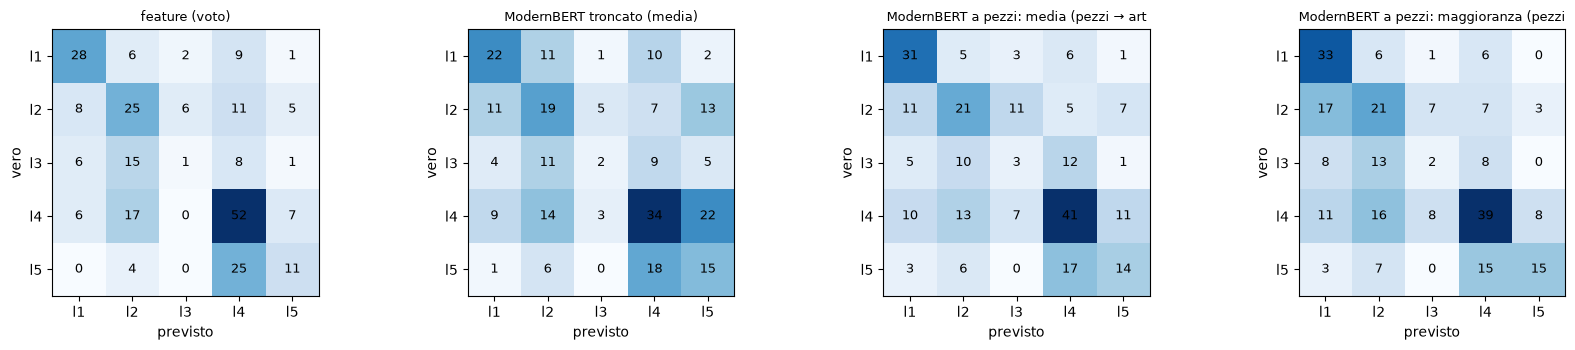

In [20]:
# matrici di confusione (righe: livello vero; colonne: livello previsto)
fig, assi = plt.subplots(1, len(scelti), figsize=(4.2 * len(scelti), 3.6))
for ax, k in zip(assi, scelti):
    M = pd.crosstab(pd.Series(val.label.to_numpy()), pd.Series(prev[k])).reindex(index=range(5), columns=range(5), fill_value=0)
    ax.imshow(M, cmap="Blues")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, M.iloc[i, j], ha="center", va="center", fontsize=9)
    ax.set_xticks(range(5), F.LIVELLI); ax.set_yticks(range(5), F.LIVELLI); ax.set_title(k[:38], fontsize=9)
    ax.set_xlabel("previsto"); ax.set_ylabel("vero")
plt.tight_layout(); plt.show()

## 10. Che cosa ne concludiamo

*(da scrivere dopo aver visto i risultati)*